Observations: 10306 | Features: ['log_line item quantity', 'log_line item value', 'log_unit price', 'log_weight (kilograms)', 'log_freight cost (usd)', 'log_line item insurance (usd)', 'log_freight_per_kg', 'log_freight_pct_of_value', 'signed_log_delay']
Explained variance ratio: [4.982e-01 1.725e-01 1.193e-01 1.055e-01 8.500e-02 1.270e-02 5.600e-03
 1.000e-03 2.000e-04]
Cumulative: [0.4982 0.6708 0.7901 0.8956 0.9806 0.9932 0.9988 0.9998 1.    ]


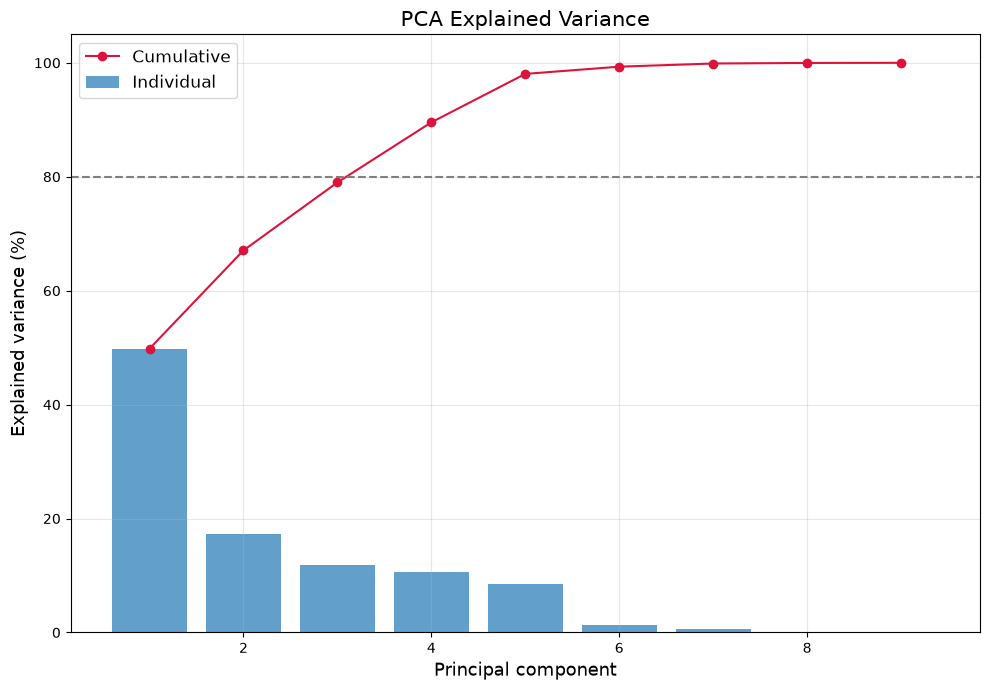

                                 PC1    PC2    PC3
log_line item quantity         0.438 -0.043 -0.136
log_line item value            0.443 -0.245  0.017
log_unit price                -0.063 -0.408  0.574
log_weight (kilograms)         0.363  0.456  0.195
log_freight cost (usd)         0.256  0.402  0.473
log_line item insurance (usd)  0.443 -0.206  0.036
log_freight_per_kg            -0.294 -0.317  0.130
log_freight_pct_of_value      -0.357  0.478  0.213
signed_log_delay              -0.010 -0.175  0.571


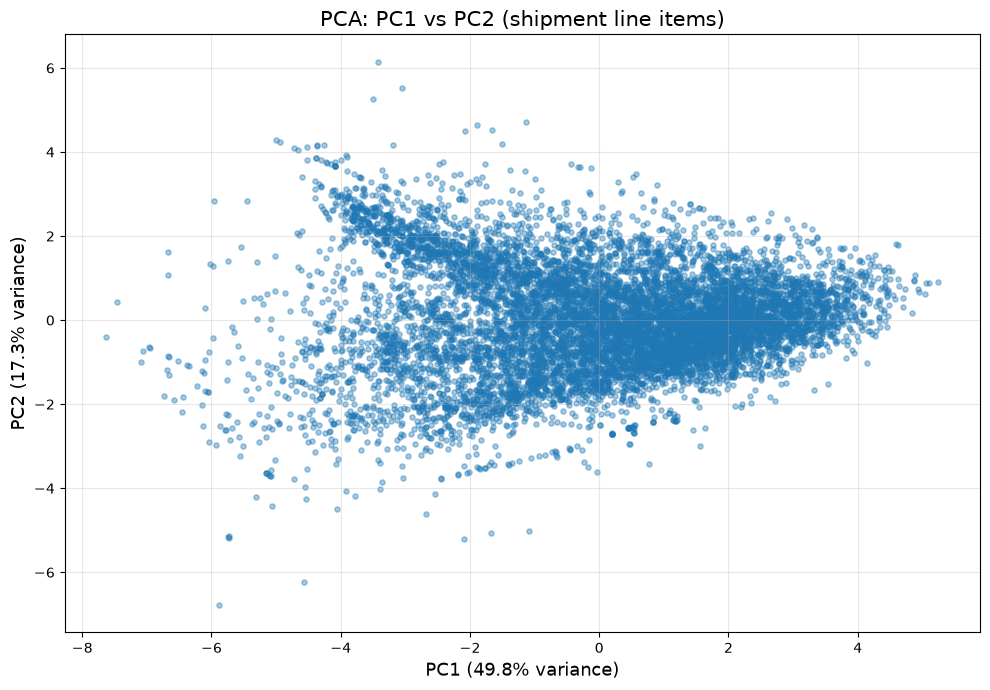

Silhouette: {2: np.float64(0.316), 3: np.float64(0.305), 4: np.float64(0.228), 5: np.float64(0.233), 6: np.float64(0.223), 7: np.float64(0.212), 8: np.float64(0.214), 9: np.float64(0.224), 10: np.float64(0.217)} -> best k = 2


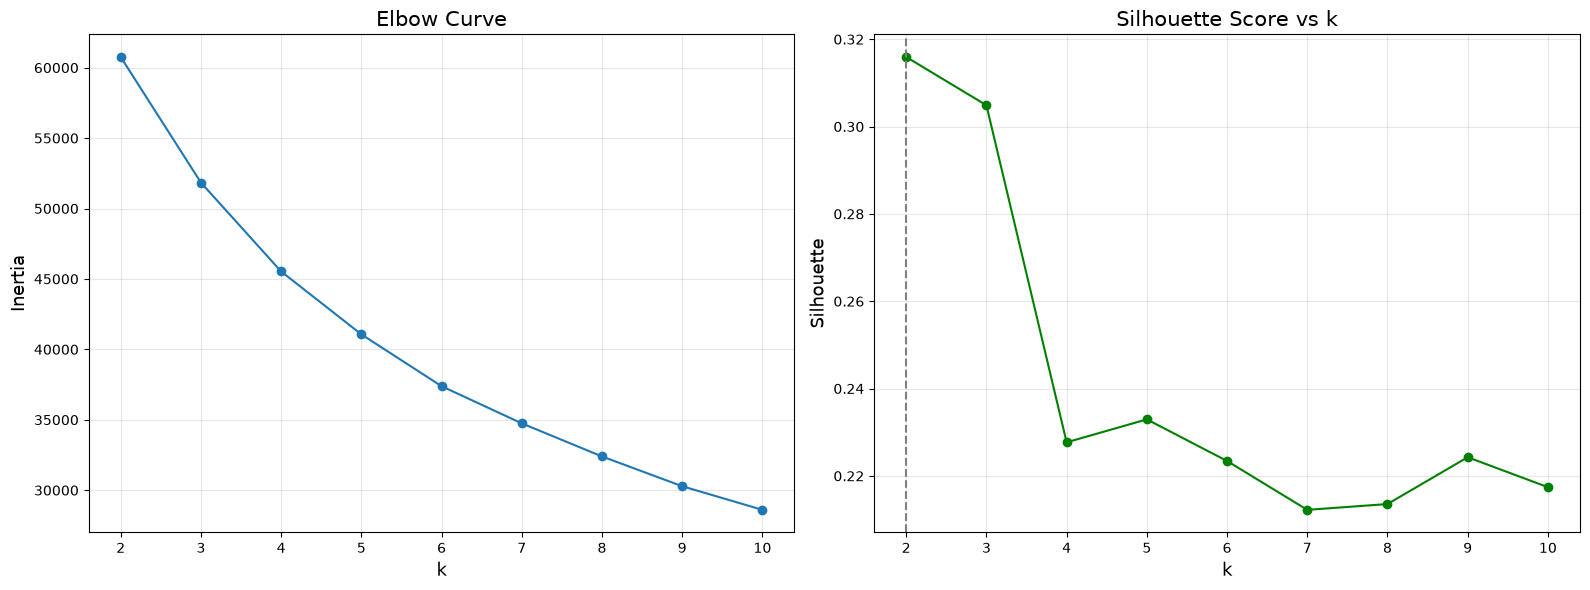

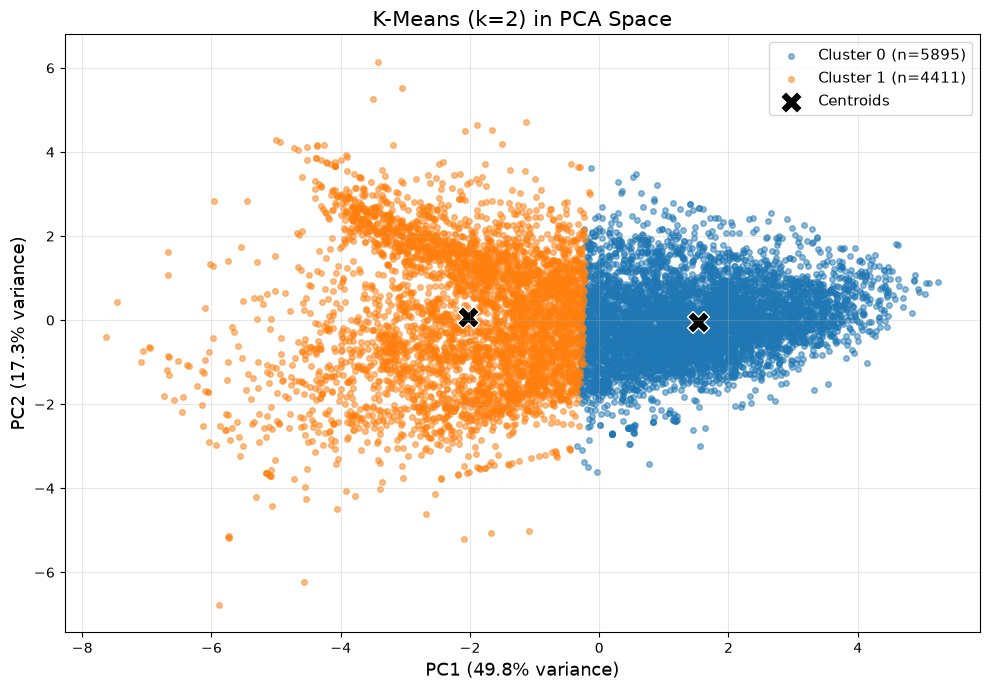

cluster                            0        1
line item quantity          12512.00   288.00
line item value            132000.00  3075.00
unit price                      0.16     0.15
weight (kilograms)           2565.00   338.00
freight cost (usd)           9535.67  4708.00
line item insurance (usd)     201.26     4.52
freight_per_kg                  4.18     9.39
freight_pct_of_value            7.52   120.98
delivery_delay_days             0.00     0.00


In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data = pd.read_csv("Supply_Chain_Shipment_Data_Cleaned.csv")

# ---- Feature selection ----
# Excluded: id, code columns, dates, delivery_year, text categoricals,
# pack price (near-duplicate of unit price), freight_status (mostly missing).
# Kept: continuous, informative, log-transformed because heavily right-skewed.
d = data.copy()
# Zero weight/value make ratios undefined and log meaningless
d = d[(d["weight (kilograms)"] > 0) & (d["line item value"] > 0)].copy()

pos_cols = ["line item quantity", "line item value", "unit price", "weight (kilograms)",
            "freight cost (usd)", "line item insurance (usd)", "freight_per_kg", "freight_pct_of_value"]
X = pd.DataFrame(index=d.index)
for c in pos_cols:
    X["log_" + c] = np.log1p(d[c])
# Delay can be negative (early delivery) -> signed log
X["signed_log_delay"] = np.sign(d["delivery_delay_days"]) * np.log1p(d["delivery_delay_days"].abs())

# Missing values: median imputation. Outliers are kept; the log transform tames them.
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
X = X.loc[:, X.std() > 1e-8]   # drop zero-variance columns if any
print("Observations:", X.shape[0], "| Features:", list(X.columns))

Xs = StandardScaler().fit_transform(X)

# ---- PCA ----
pca_full = PCA().fit(Xs)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
print("Explained variance ratio:", np.round(evr, 4))
print("Cumulative:", np.round(cum, 4))

plt.figure(figsize=(10, 7))
plt.bar(range(1, len(evr)+1), evr*100, alpha=0.7, label="Individual")
plt.plot(range(1, len(evr)+1), cum*100, "o-", color="crimson", label="Cumulative")
plt.axhline(80, ls="--", color="gray")
plt.xlabel("Principal component", fontsize=13)
plt.ylabel("Explained variance (%)", fontsize=13)
plt.title("PCA Explained Variance", fontsize=15)
plt.legend(fontsize=12); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

pca = PCA(n_components=3).fit(Xs)
P = pca.transform(Xs)
v = pca.explained_variance_ratio_ * 100
print(pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"]).round(3))

plt.figure(figsize=(10, 7))
plt.scatter(P[:, 0], P[:, 1], s=14, alpha=0.4)
plt.xlabel(f"PC1 ({v[0]:.1f}% variance)", fontsize=13)
plt.ylabel(f"PC2 ({v[1]:.1f}% variance)", fontsize=13)
plt.title("PCA: PC1 vs PC2 (shipment line items)", fontsize=15)
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- Clustering (on the full standardized feature space; PCA used for visualization) ----
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_, sample_size=5000, random_state=42))
best_k = list(ks)[int(np.argmax(sil))]
print("Silhouette:", dict(zip(ks, np.round(sil, 3))), "-> best k =", best_k)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].plot(list(ks), inertia, "o-")
ax[0].set_title("Elbow Curve", fontsize=15); ax[0].set_xlabel("k", fontsize=13)
ax[0].set_ylabel("Inertia", fontsize=13); ax[0].grid(alpha=0.3)
ax[1].plot(list(ks), sil, "o-", color="green"); ax[1].axvline(best_k, ls="--", color="gray")
ax[1].set_title("Silhouette Score vs k", fontsize=15); ax[1].set_xlabel("k", fontsize=13)
ax[1].set_ylabel("Silhouette", fontsize=13); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xs)
labels = km.labels_
cent = pca.transform(km.cluster_centers_)   # centroids projected into PCA space

plt.figure(figsize=(10, 7))
cmap = plt.cm.tab10
for c in range(best_k):
    m = labels == c
    plt.scatter(P[m, 0], P[m, 1], s=16, alpha=0.5, color=cmap(c), label=f"Cluster {c} (n={m.sum()})")
plt.scatter(cent[:, 0], cent[:, 1], marker="X", s=250, c="black", edgecolor="white", label="Centroids")
plt.xlabel(f"PC1 ({v[0]:.1f}% variance)", fontsize=13)
plt.ylabel(f"PC2 ({v[1]:.1f}% variance)", fontsize=13)
plt.title(f"K-Means (k={best_k}) in PCA Space", fontsize=15)
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Cluster profile (original units, medians)
print(d.assign(cluster=labels).groupby("cluster")[pos_cols + ["delivery_delay_days"]].median().round(2).T)

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mutual_info_score

K = 3                       # silhouette for k=2 (~0.32) and k=3 (~0.31) are nearly tied; k=3 gives a more informative split
EXCLUDE_PLACEHOLDERS = False  # True: re-run clustering only on rows whose weight/freight are NOT the dataset's filler values

# ---------- 1. Rebuild the same feature space as before ----------
d = data.copy()
d = d[(d["weight (kilograms)"] > 0) & (d["line item value"] > 0)].copy()

# Filler detection: the single most common weight / freight value is far more frequent than any other
# (the "cleaned" file appears to have filled missing weight/freight with a median). Flag, don't delete.
w_mode = d["weight (kilograms)"].mode()[0]; f_mode = d["freight cost (usd)"].mode()[0]
d["weight_is_filler"] = d["weight (kilograms)"] == w_mode
d["freight_is_filler"] = d["freight cost (usd)"] == f_mode
print(f"Filler weight={w_mode}: {d.weight_is_filler.mean():.1%} of rows | filler freight={f_mode}: {d.freight_is_filler.mean():.1%}")
if EXCLUDE_PLACEHOLDERS:
    d = d[~d.weight_is_filler & ~d.freight_is_filler].copy()

pos_cols = ["line item quantity", "line item value", "unit price", "weight (kilograms)",
            "freight cost (usd)", "line item insurance (usd)", "freight_per_kg", "freight_pct_of_value"]
X = pd.DataFrame(index=d.index)
for c in pos_cols:
    X["log " + c] = np.log1p(d[c])
X["signed log delay"] = np.sign(d["delivery_delay_days"]) * np.log1p(d["delivery_delay_days"].abs())
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
Xs = StandardScaler().fit_transform(X)

pca = PCA(n_components=2).fit(Xs); P = pca.transform(Xs); v = pca.explained_variance_ratio_ * 100
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
d["cluster"] = km.labels_
print("Silhouette (5000-row sample):", round(silhouette_score(Xs, km.labels_, sample_size=5000, random_state=42), 3))
cl = sorted(d.cluster.unique()); colors = plt.cm.tab10
size = d.cluster.value_counts().sort_index()

# ---------- 2. Quantitative profile (original units) ----------
prof_cols = ["line item value", "line item quantity", "weight (kilograms)", "freight cost (usd)",
             "freight_pct_of_value", "freight_per_kg", "unit price", "delivery_delay_days"]
print("\nCluster sizes:\n", pd.DataFrame({"n": size, "pct": (size / len(d) * 100).round(1)}))
prof = d.groupby("cluster")[prof_cols].agg(["mean", "median", "std",
        lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
prof.columns = [f"{a} | {'q25' if '<lambda_0>' in b else 'q75' if '<lambda_1>' in b else b}" for a, b in prof.columns]
pd.set_option("display.width", 250, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)
print("\nNumeric profile:\n", prof.T)
d["late"] = d.delivery_delay_days > 0
print("\nShare of late deliveries by cluster:\n", d.groupby("cluster").late.mean().round(3))

# ---------- 3. What differentiates clusters ----------
# Numeric: Kruskal-Wallis + epsilon^2 effect size (H/(n-1)); robust to the skew
rows = []
for c in prof_cols + ["line item insurance (usd)"]:
    H, p = stats.kruskal(*[g[c].dropna() for _, g in d.groupby("cluster")])
    rows.append((c, H, p, H / (len(d) - 1)))
kw = pd.DataFrame(rows, columns=["variable", "H", "p", "epsilon2"]).sort_values("epsilon2", ascending=False)
print("\nNumeric differences (epsilon2: ~.01 small, .06 medium, .14+ large):\n", kw.to_string(index=False))

# Categorical: Cramer's V + mutual information
cat_cols = ["shipment mode", "vendor inco term", "fulfill via", "product group", "delivery_status",
            "first line designation", "country", "delivery_year", "vendor", "manufacturing site",
            "weight_is_filler", "freight_is_filler"]
rows = []
for c in cat_cols:
    s = d[c].astype(str).fillna("NA"); ct = pd.crosstab(s, d.cluster)
    with np.errstate(all="ignore"):
        chi2 = stats.chi2_contingency(ct)[0]
        V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append((c, s.nunique(), V, mutual_info_score(s, d.cluster)))
cv = pd.DataFrame(rows, columns=["variable", "n_levels", "CramersV", "mutual_info"]).sort_values("CramersV", ascending=False)
print("\nCategorical associations (high-cardinality columns inflate V; read with care):\n", cv.to_string(index=False))

for c in ["shipment mode", "vendor inco term", "fulfill via", "product group", "delivery_status"]:
    print(f"\n{c} (column %):\n", (pd.crosstab(d[c].fillna("NA"), d.cluster, normalize="columns") * 100).round(1))
print("\nFiller flags (% of cluster):\n", d.groupby("cluster")[["weight_is_filler", "freight_is_filler"]].mean().mul(100).round(1))
top_c = d.country.value_counts().index[:8]
print("\nCountry share (column %), top-8 countries:\n",
      (pd.crosstab(d.country, d.cluster, normalize="columns") * 100).round(1).loc[top_c])
print("\nShare of each country's rows in each cluster (row %), top-8 countries:\n",
      (pd.crosstab(d.country, d.cluster, normalize="index") * 100).round(1).loc[top_c])
print("\nYear mix (row %):\n", (pd.crosstab(d.cluster, d.delivery_year, normalize="index") * 100).round(1))

# ---------- 4. Anomalies: distance to own centroid ----------
d["dist"] = np.linalg.norm(Xs - km.cluster_centers_[km.labels_], axis=1)
print("\nDistance to centroid by cluster:\n", d.groupby("cluster").dist.describe().round(2))
thr = d.groupby("cluster").dist.transform(lambda s: s.quantile(.99))
far = d[d.dist > thr]
print("\nTop-1% farthest rows per cluster (medians):\n",
      far.groupby("cluster")[["line item value", "weight (kilograms)", "freight cost (usd)", "freight_pct_of_value", "delivery_delay_days"]].median().round(1))
print("Most extreme rows overall:\n", d.nlargest(8, "dist")[["country", "product group", "line item value", "weight (kilograms)",
      "freight cost (usd)", "freight_pct_of_value", "delivery_delay_days", "cluster", "dist"]])

# ---------- 5. Visualizations ----------
# (a) PCA scatter, SPATIALLY AGGREGATED for display only (clustering used all rows)
nb = 45
bx = pd.cut(P[:, 0], nb, labels=False); by = pd.cut(P[:, 1], nb, labels=False)
b = pd.DataFrame({"x": P[:, 0], "y": P[:, 1], "bin": bx * nb + by, "cl": d.cluster.values})
agg = b.groupby("bin").agg(x=("x", "mean"), y=("y", "mean"), n=("x", "size"), cl=("cl", lambda s: s.mode()[0]),
                           purity=("cl", lambda s: s.value_counts(normalize=True).iloc[0]))
print(f"\nPlot bins: {len(agg)} bins for {len(b)} rows; mean bin purity {np.average(agg.purity, weights=agg.n):.2f}")
plt.figure(figsize=(11, 8))
for c in cl:
    a = agg[agg.cl == c]
    plt.scatter(a.x, a.y, s=15 + 14 * np.sqrt(a.n), color=colors(c), alpha=.6, edgecolor="white", lw=.4,
                label=f"Cluster {c} (n={size[c]:,})")
cent = pca.transform(km.cluster_centers_)
plt.scatter(cent[:, 0], cent[:, 1], marker="X", s=300, c="black", edgecolor="white", label="Centroids")
plt.xlabel(f"PC1 ({v[0]:.1f}% variance)", fontsize=13); plt.ylabel(f"PC2 ({v[1]:.1f}% variance)", fontsize=13)
plt.title(f"K-Means (k={K}) in PCA space\nEach point = a {nb}x{nb} grid bin (mean position of nearby shipments, size = count; colour = majority cluster)", fontsize=13)
plt.legend(fontsize=11); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# (b) Standardized profile heatmap (cluster mean of z-scored features)
z = pd.DataFrame(Xs, columns=X.columns, index=d.index).groupby(d.cluster).mean()
plt.figure(figsize=(11, 4.5)); im = plt.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
plt.xticks(range(z.shape[1]), z.columns, rotation=40, ha="right"); plt.yticks(range(len(z)), [f"Cluster {c}" for c in z.index])
for i in range(z.shape[0]):
    for j in range(z.shape[1]): plt.text(j, i, f"{z.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
plt.colorbar(im, label="mean z-score"); plt.title("Cluster profile (standardized, log-scale features)", fontsize=14)
plt.tight_layout(); plt.show()

# (c) Boxplots of key variables by cluster (log axis)
key = ["line item value", "weight (kilograms)", "freight cost (usd)", "freight_pct_of_value", "freight_per_kg", "line item quantity"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), key):
    ax.boxplot([d.loc[d.cluster == k, c].clip(lower=1e-2) for k in cl], showfliers=False)
    ax.set_xticks(range(1, len(cl) + 1)); ax.set_xticklabels([f"C{k}" for k in cl])
    ax.set_yscale("log"); ax.set_title(c, fontsize=13); ax.grid(alpha=.3)
fig.suptitle("Key variables by cluster (log scale, outliers hidden for readability only)", fontsize=15)
plt.tight_layout(); plt.show()

# (d) Categorical composition
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, c in zip(axes.ravel(), ["shipment mode", "vendor inco term", "first line designation", "delivery_status"]):
    (pd.crosstab(d.cluster, d[c].astype(str), normalize="index") * 100).plot(kind="bar", stacked=True, ax=ax, colormap="tab20", rot=0)
    ax.set_title(f"{c} by cluster", fontsize=13); ax.set_ylabel("% of cluster"); ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

# (e) Country and year composition
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
(pd.crosstab(d.country, d.cluster, normalize="index") * 100).loc[top_c].plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", rot=40)
axes[0].set_title("Top-8 countries: % of shipments per cluster"); axes[0].set_ylabel("%")
(pd.crosstab(d.delivery_year, d.cluster, normalize="index") * 100).plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", rot=0)
axes[1].set_title("Delivery year: % of shipments per cluster"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

# (f) Value vs weight, coloured by cluster (alpha handles overplotting; all rows shown)
plt.figure(figsize=(10, 7))
for c in cl:
    m = d.cluster == c
    plt.scatter(d.loc[m, "line item value"], d.loc[m, "weight (kilograms)"], s=8, alpha=.25, color=colors(c), label=f"Cluster {c}")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Line item value (USD, log)", fontsize=13); plt.ylabel("Weight (kg, log)", fontsize=13)
plt.title("Value vs weight by cluster (horizontal stripe = filler weight)", fontsize=14)
plt.legend(markerscale=3, fontsize=11); plt.grid(alpha=.3); plt.tight_layout(); plt.show()